In [28]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import textwrap

sns.set_theme(style="whitegrid")
RED, GREEN, BLUE, AMBER = "#B23B32", "#3F8B5D", "#3D5A99", "#B9821E"

def story_title(text, size=12, **kw):
    width = int(plt.gcf().get_figwidth() * 7.2)                 
    plt.title(textwrap.fill(text, width), fontsize=size, weight="bold", **kw)
    
    
fig_dir = "../outputs/figures"
dataset = pd.read_csv("../data/processed/smart_waste_dataset_cleaned.csv", parse_dates=["ArrivalDate", "ExpiryDate"])


In [29]:
raw = dataset
raw["BatchID"] = (raw["ItemName"] + "|" + raw["StockQty"].astype(str) + "|" +
                  raw["ArrivalDate"].dt.strftime("%m%d") + "|" + raw["ExpiryDate"].dt.strftime("%m%d"))

cols = ["Category", "ItemName", "StockQty", "DailySaleAvg", "OnPromotion", "TemperatureSensitive", "StoreLocation", "IsSpoiled"]
print("Columns that differ between copies of the same batch:", [c for c in cols if (raw.groupby("BatchID")[c].nunique() > 1).any()] or "none")

batch = raw.groupby("BatchID").agg(**{c: (c, "first") for c in cols}, Arrival=("ArrivalDate", "min"), Expiry=("ExpiryDate", "first"), Copies=("BatchID", "size")).reset_index()
print("Raw rows:", len(raw), "| batches:", len(batch))

Columns that differ between copies of the same batch: none
Raw rows: 1000 | batches: 50


In [30]:
AS_OF = pd.Timestamp("2025-06-28")  

batch["Known"] = batch["Expiry"] < AS_OF
b = batch[batch["Known"]].copy()
b["Outcome"] = b["IsSpoiled"].map({True: "Spoiled", False: "Did not spoil", 1: "Spoiled", 0: "Did not spoil"})
b["SpoiledFlag"] = (b["Outcome"] == "Spoiled").astype(int)
n_total, n_kept, n_sp = len(batch), len(b), int(b["SpoiledFlag"].sum())
print(f"{n_kept} of {n_total} batches have a known outcome: {n_sp} spoiled, {n_kept - n_sp} did not spoil")

28 of 50 batches have a known outcome: 17 spoiled, 11 did not spoil


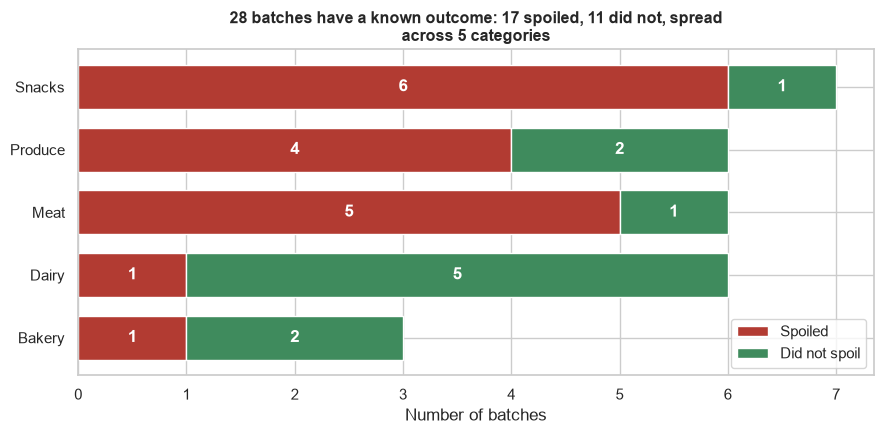

In [31]:
counts = pd.crosstab(b["Category"], b["Outcome"]).reindex(columns=["Spoiled", "Did not spoil"], fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]
ax = counts.plot(kind="barh", stacked=True, color=[RED, GREEN], figsize=(9, 4.5), width=0.7)
for c in ax.containers: ax.bar_label(c, label_type="center", color="white", fontweight="bold", fmt=lambda v: f"{int(v)}" if v > 0 else "")

story_title(f"{n_kept} batches have a known outcome: {n_sp} spoiled, {n_kept - n_sp} did not, spread across {b['Category'].nunique()} categories", size=11.5)
plt.xlabel("Number of batches"); plt.ylabel(""); plt.legend(title="")
plt.tight_layout(); 

plt.savefig(f"{fig_dir}/eda_batches_by_category.png", dpi=150); plt.show()

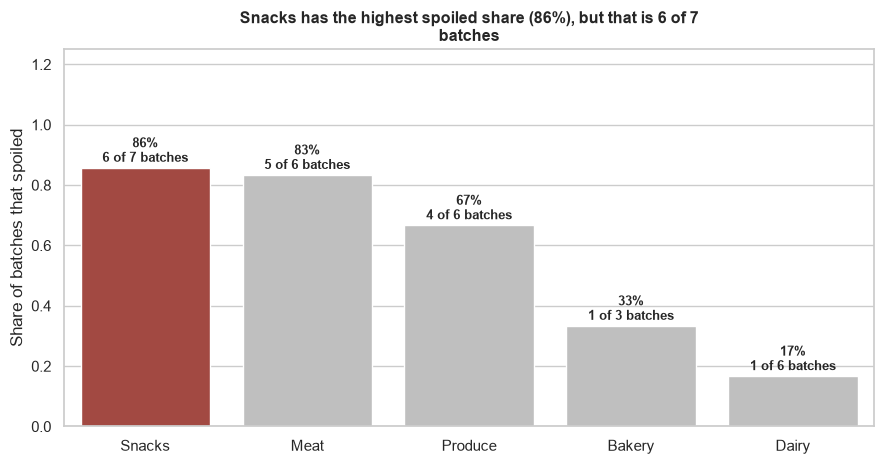

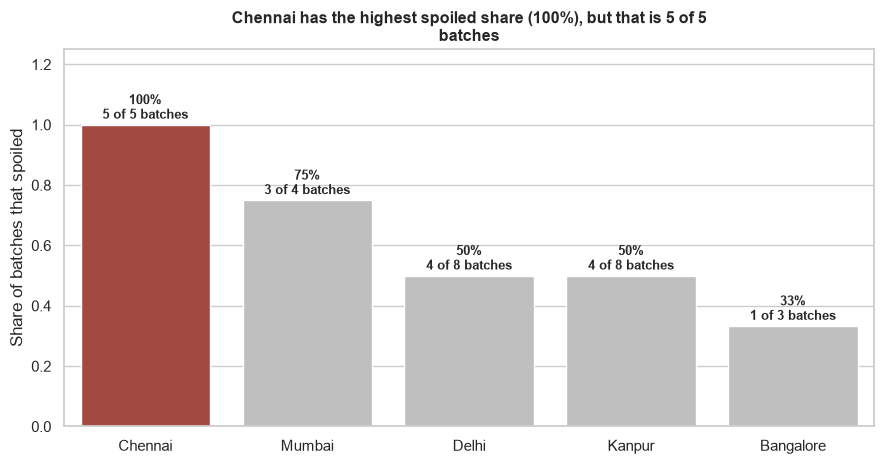

In [32]:
def share_chart(col, filename):
    g = b.groupby(col).agg(spoiled=("SpoiledFlag", "sum"), n=("SpoiledFlag", "size")).reset_index()
    g["share"] = g["spoiled"] / g["n"]
    g = g.sort_values("share", ascending=False)
    plt.figure(figsize=(9, 4.8))
    ax = sns.barplot(data=g, x=col, y="share", hue=col, palette=[RED if i == 0 else "#BFBFBF" for i in range(len(g))], legend=False)
    
    for i, r in enumerate(g.itertuples()):
        ax.text(i, r.share + 0.02, f"{r.share:.0%}\n{int(r.spoiled)} of {int(r.n)} batches", ha="center", fontweight="bold", fontsize=9)
    plt.ylim(0, 1.25); plt.xlabel(""); plt.ylabel("Share of batches that spoiled")
    top = g.iloc[0]
    story_title(f"{top[col]} has the highest spoiled share ({top['share']:.0%}), but that is {int(top['spoiled'])} of {int(top['n'])} batches", size=11.5)
    
    plt.tight_layout(); plt.savefig(f"{fig_dir}/{filename}", dpi=150); plt.show()
share_chart("Category", "eda_share_by_category.png")
share_chart("StoreLocation", "eda_share_by_store.png")

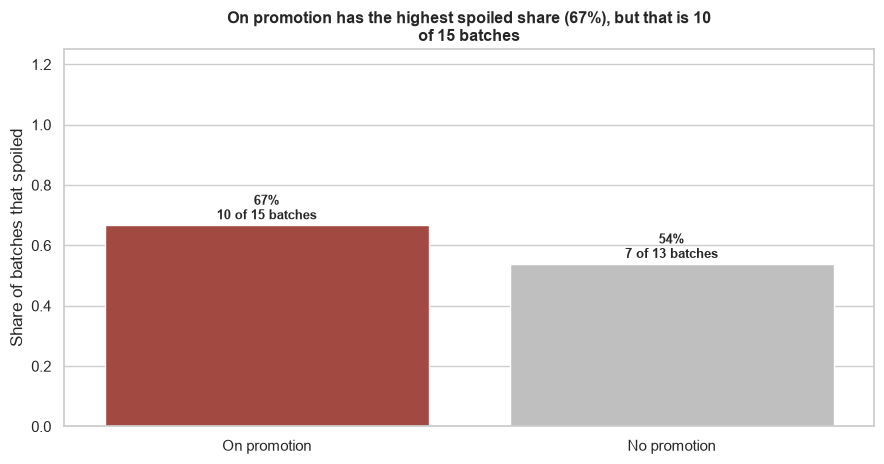

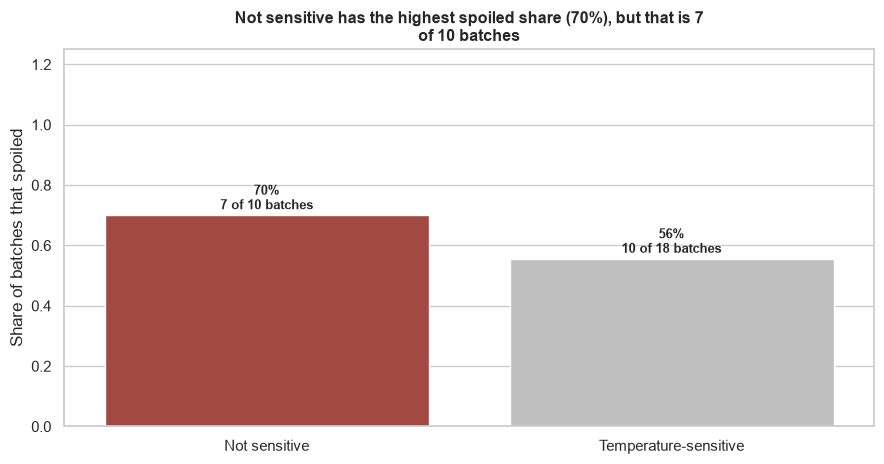

In [33]:
b["Promotion"] = b["OnPromotion"].map({True: "On promotion", False: "No promotion", 1: "On promotion", 0: "No promotion"})
b["Temperature"] = b["TemperatureSensitive"].map({True: "Temperature-sensitive", False: "Not sensitive", 1: "Temperature-sensitive", 0: "Not sensitive"})
share_chart("Promotion", "eda_share_by_promotion.png")
share_chart("Temperature", "eda_share_by_temperature.png")

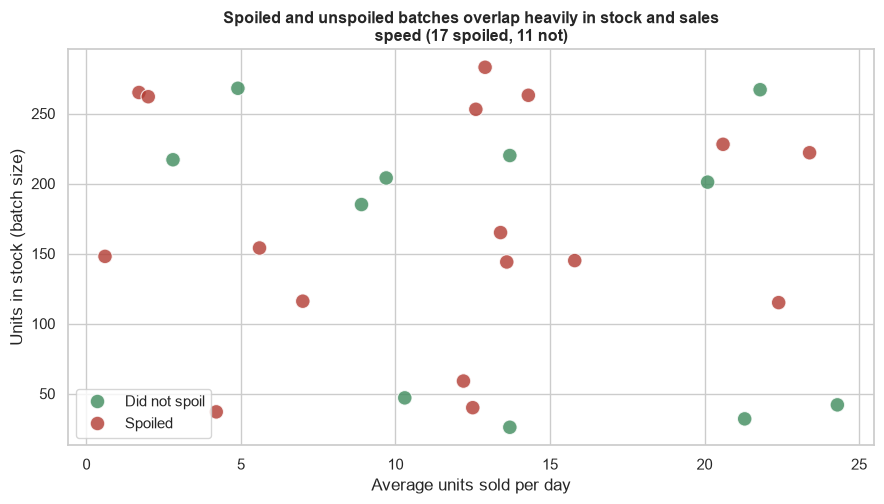

In [34]:
plt.figure(figsize=(9, 5.2))
sns.scatterplot(data=b, x="DailySaleAvg", y="StockQty", hue="Outcome", palette={"Spoiled": RED, "Did not spoil": GREEN}, s=110, alpha=0.8)
plt.xlabel("Average units sold per day"); plt.ylabel("Units in stock (batch size)")
story_title(f"Spoiled and unspoiled batches overlap heavily in stock and sales speed ({n_sp} spoiled, {n_kept - n_sp} not)", size=11.5)
plt.legend(title=""); plt.tight_layout(); plt.savefig(f"{fig_dir}/eda_stock_vs_sales.png", dpi=150); plt.show()

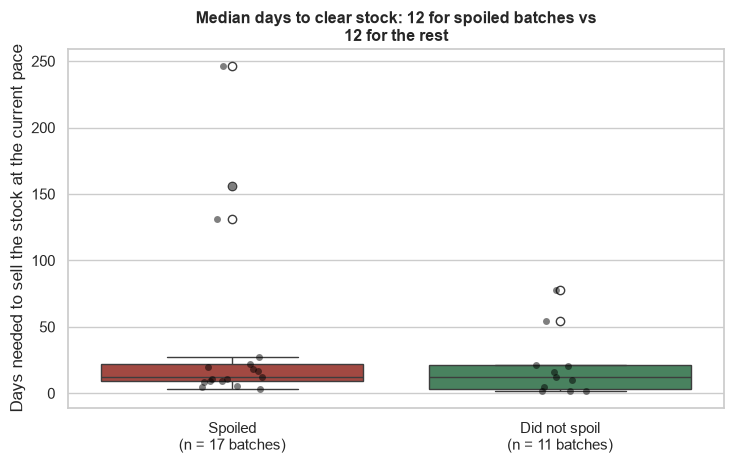

In [35]:
b["DaysToClear"] = b["StockQty"] / b["DailySaleAvg"]
plt.figure(figsize=(7.5, 4.8))
sns.boxplot(data=b, x="Outcome", y="DaysToClear", hue="Outcome", palette={"Spoiled": RED, "Did not spoil": GREEN}, order=["Spoiled", "Did not spoil"], legend=False)
sns.stripplot(data=b, x="Outcome", y="DaysToClear", color="black", alpha=0.5, order=["Spoiled", "Did not spoil"])
ns = b["Outcome"].value_counts()

plt.xticks([0, 1], [f"Spoiled\n(n = {ns.get('Spoiled', 0)} batches)", f"Did not spoil\n(n = {ns.get('Did not spoil', 0)} batches)"])
plt.xlabel(""); plt.ylabel("Days needed to sell the stock at the current pace")
med = b.groupby("Outcome")["DaysToClear"].median()

story_title(f"Median days to clear stock: {med.get('Spoiled', np.nan):.0f} for spoiled batches vs {med.get('Did not spoil', np.nan):.0f} for the rest", size=11.5)
plt.tight_layout(); 
plt.savefig(f"{fig_dir}/eda_days_to_clear.png", dpi=150); plt.show()

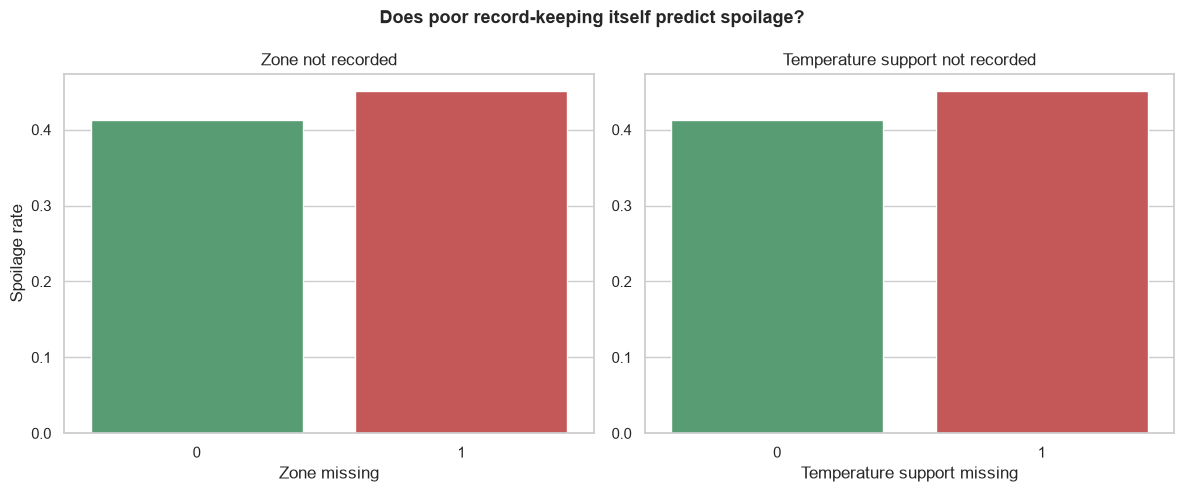

In [36]:
fig, axes = plt.subplots(1,2, figsize=(12, 5))

zone_rate = dataset.groupby("Zone_Missing")["IsSpoiled"].mean()
sns.barplot(
    x = zone_rate.index,
    y = zone_rate.values, 
    hue = zone_rate.index,
    palette = color_risk_palette, 
    legend = False, 
    ax = axes[0]
)

axes[0].set_title("Zone not recorded")
axes[0].set_xlabel("Zone missing")
axes[0].set_ylabel("Spoilage rate")

temp_support_rate = dataset.groupby("TemperatureSupport_Missing")["IsSpoiled"].mean()
sns.barplot(
    x = temp_support_rate.index, 
    y = temp_support_rate.values,
    hue = temp_support_rate.index,
    palette = color_risk_palette,
    legend = False, 
    ax = axes[1]
)

axes[1].set_title("Temperature support not recorded")
axes[1].set_xlabel("Temperature support missing")
axes[1].set_ylabel("")

fig.suptitle("Does poor record-keeping itself predict spoilage?", fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/spoilage_by_missingness.png", dpi=150)
plt.show()

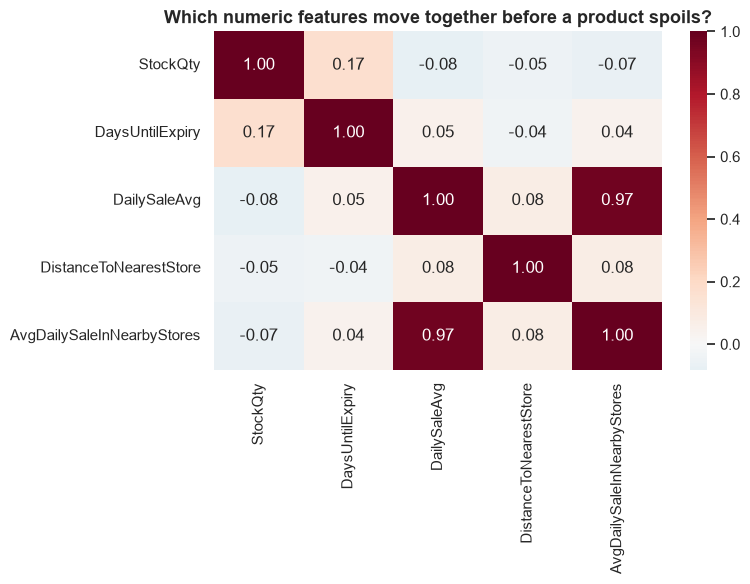

In [37]:
numeric_cols = ["StockQty", "DaysUntilExpiry", "DailySaleAvg", "DistanceToNearestStore", "AvgDailySaleInNearbyStores"]

corr_matrix = dataset[numeric_cols].corr()
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot = True, 
    fmt = ".2f",
    cmap = "RdBu_r",
    center = 0
)

plt.title("Which numeric features move together before a product spoils?", fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/correlation_heatmap.png", dpi=150)
plt.show()